# Fetal Health Classification

Reproducible CTG classification experiments using 21 predefined CTG predictors plus the engineered TotalDecelerationBurden feature (DL + DS + DP). Run the notebook from top to bottom to rebuild the plots, comparisons, and selected model.

## Dataset and setup

In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

DECELERATION_COLS = ["DL", "DS", "DP"]
DERIVED_FEATURE = "TotalDecelerationBurden"
FEATURE_COLS = [
    "LB", "AC", "FM", "UC", "DL", "DS", "DP", "ASTV", "MSTV", "ALTV",
    "MLTV", "Width", "Min", "Max", "Nmax", "Nzeros", "Mode", "Mean",
    "Median", "Variance", "Tendency", DERIVED_FEATURE,
]

PLOT_DIR = Path("../results/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)
data_path = Path("../data/CTG.xls")
df = pd.read_excel(data_path, sheet_name="Raw Data")
df = df.dropna(subset=["NSP"]).copy()
df["NSP"] = df["NSP"].astype(int)

missing_deceleration_features = sorted(set(DECELERATION_COLS) - set(df.columns))
if missing_deceleration_features:
    raise ValueError(
        "CTG workbook is missing features required to calculate "
        f"{DERIVED_FEATURE}: {missing_deceleration_features}"
    )
df[DERIVED_FEATURE] = df[DECELERATION_COLS].sum(axis=1)

missing_features = sorted(set(FEATURE_COLS) - set(df.columns))
if missing_features:
    raise ValueError(f"CTG workbook is missing expected features: {missing_features}")

X = df.loc[:, FEATURE_COLS].copy()
y = df["NSP"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Dataset shape:", df.shape)
print("Feature count:", len(FEATURE_COLS))
print("Features:", FEATURE_COLS)
print("Missing feature values:", int(X.isna().sum().sum()))
print("Class distribution:\n", y.value_counts().sort_index())

Dataset shape: (2126, 41)
Feature count: 22
Features: ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency', 'TotalDecelerationBurden']
Missing feature values: 0
Class distribution:
 NSP
1    1655
2     295
3     176
Name: count, dtype: int64


## Exploratory analysis and feature importance

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="NSP", palette="Set2")


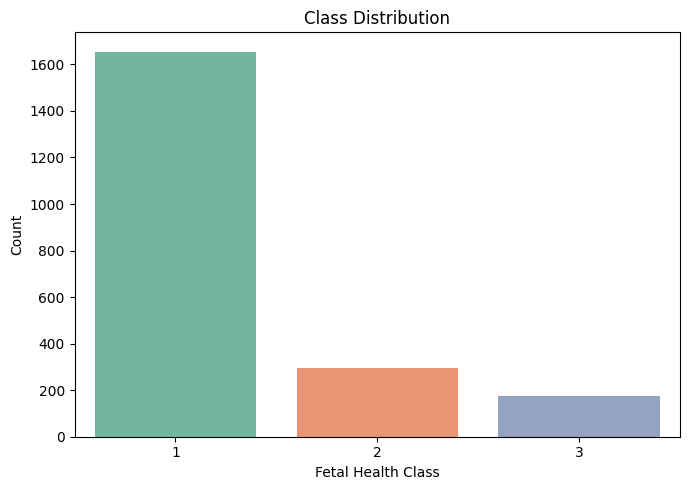

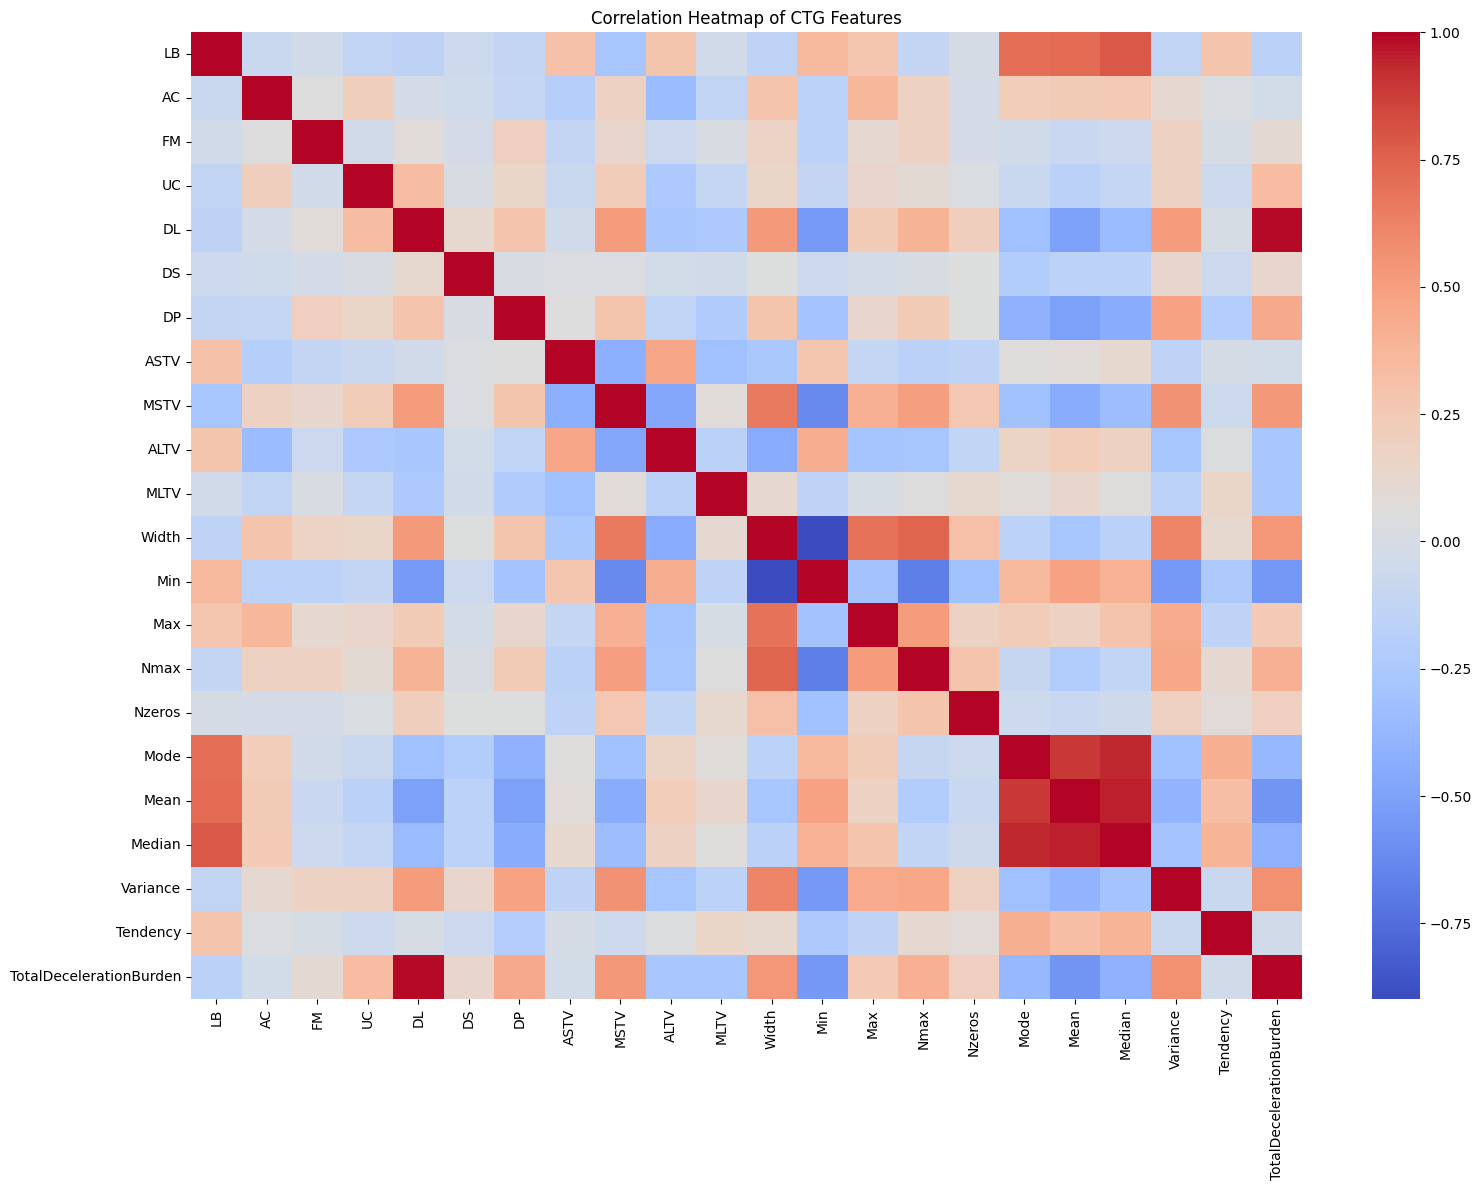

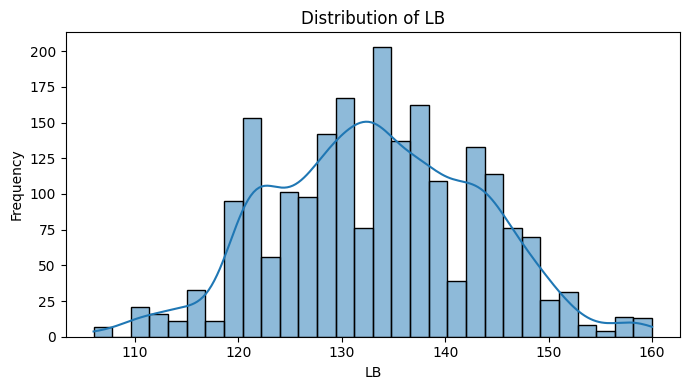

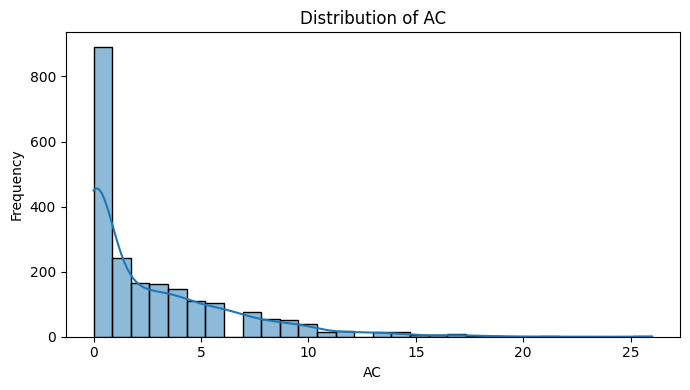

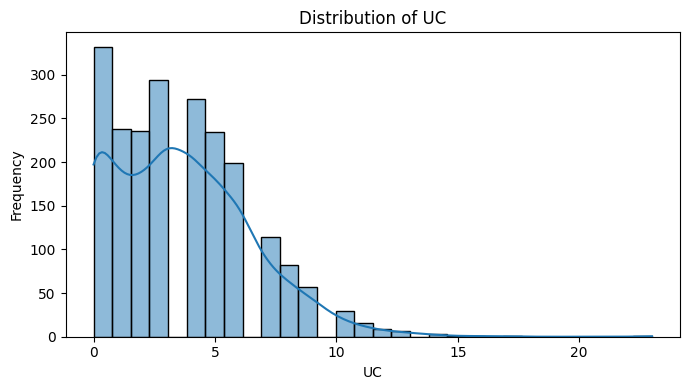

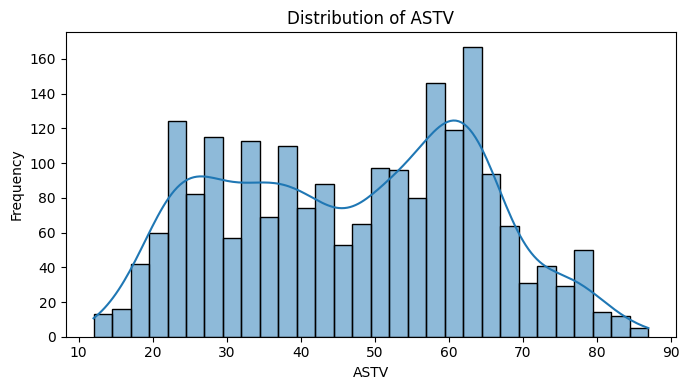

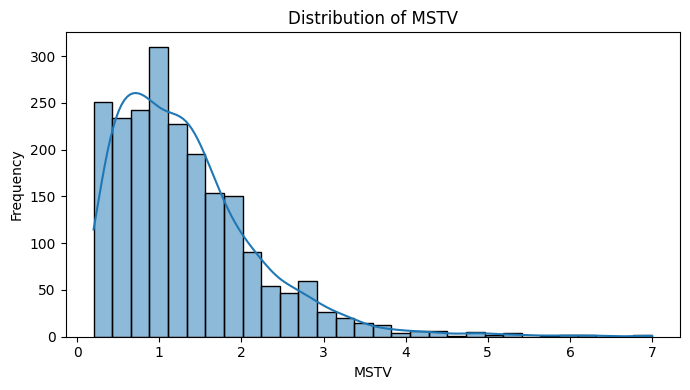

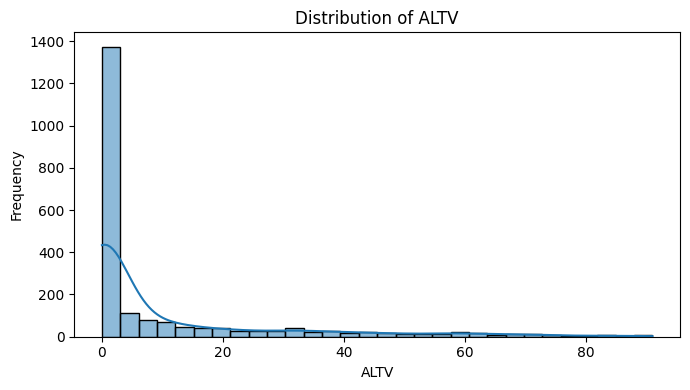

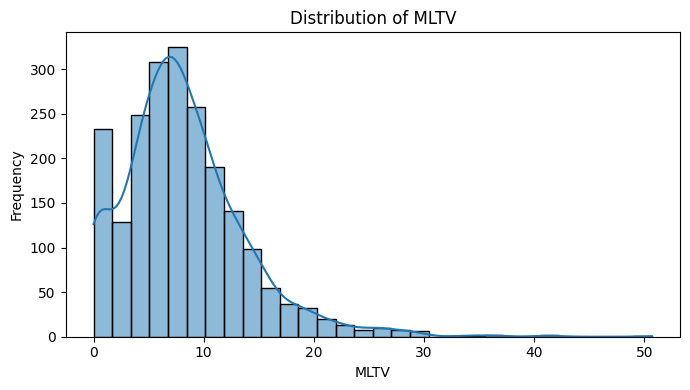

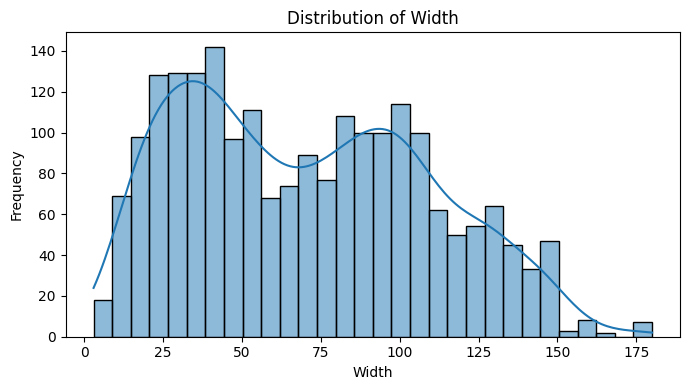

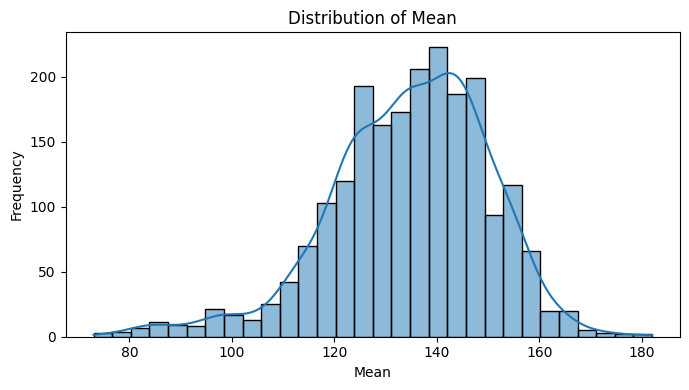

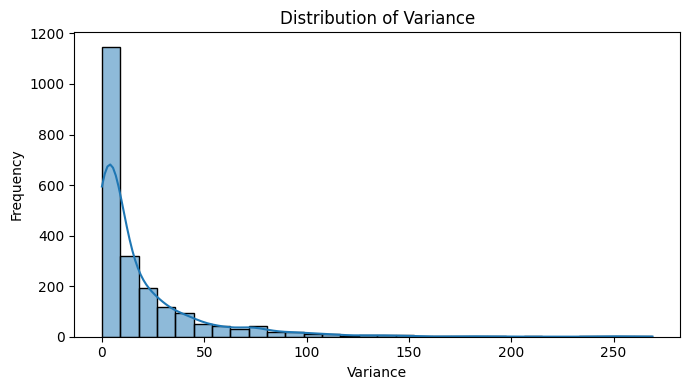

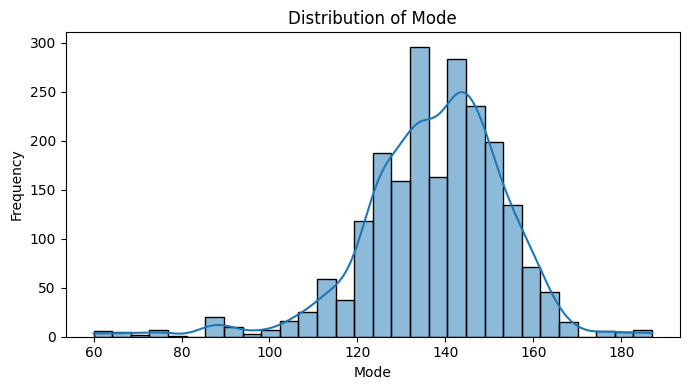

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


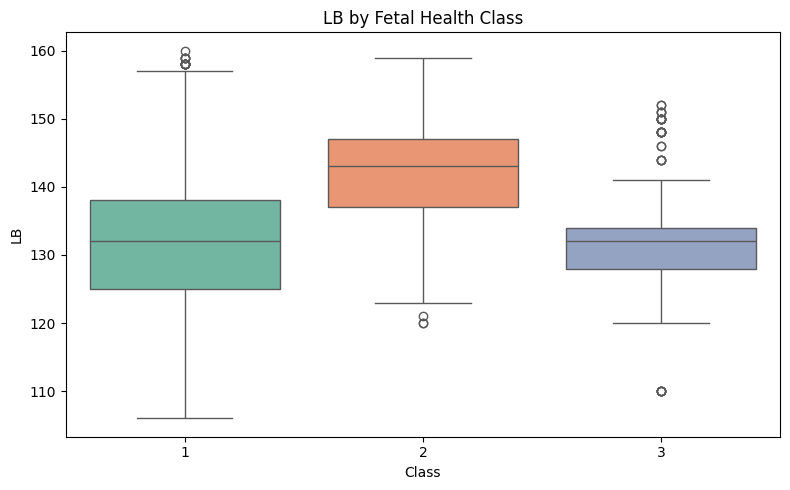

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


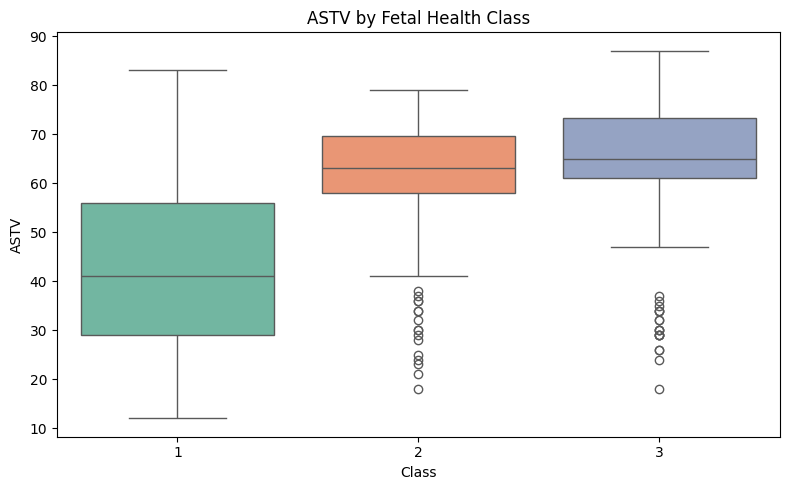

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


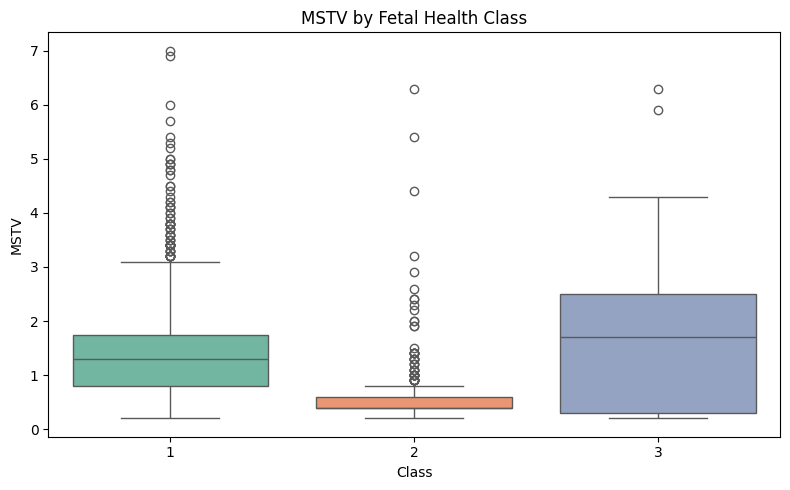

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


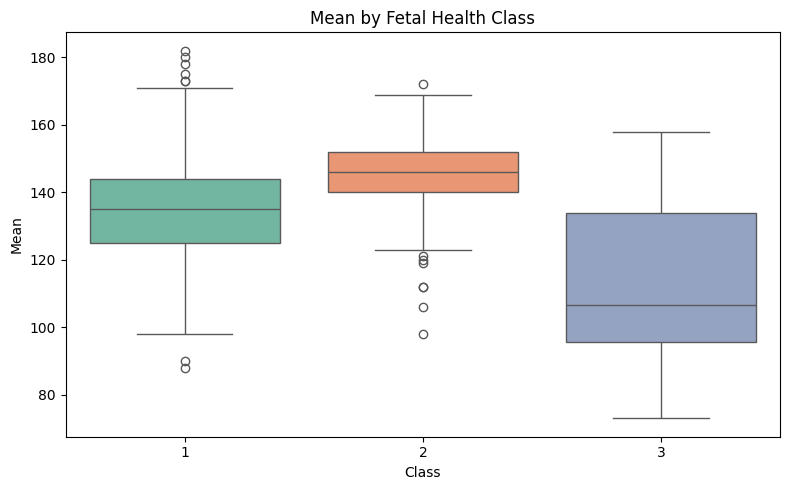

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


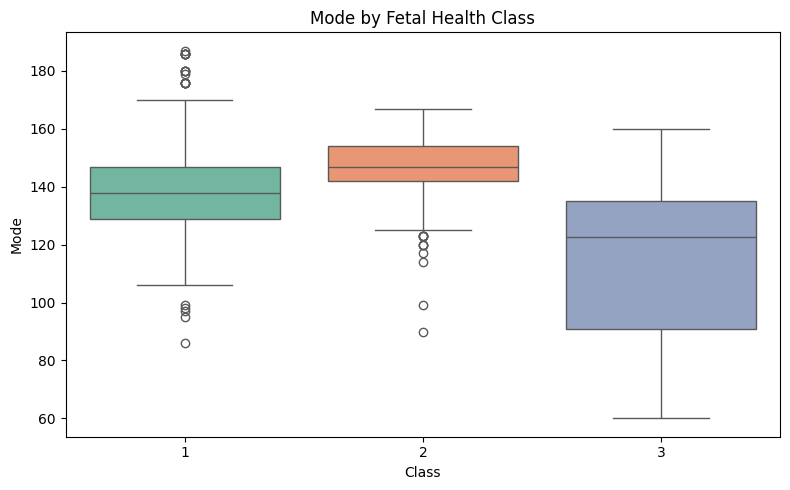

C:\Users\SABVMCRI\AppData\Local\Temp\ipykernel_27536\4070014361.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="NSP", y=col, palette="Set2")


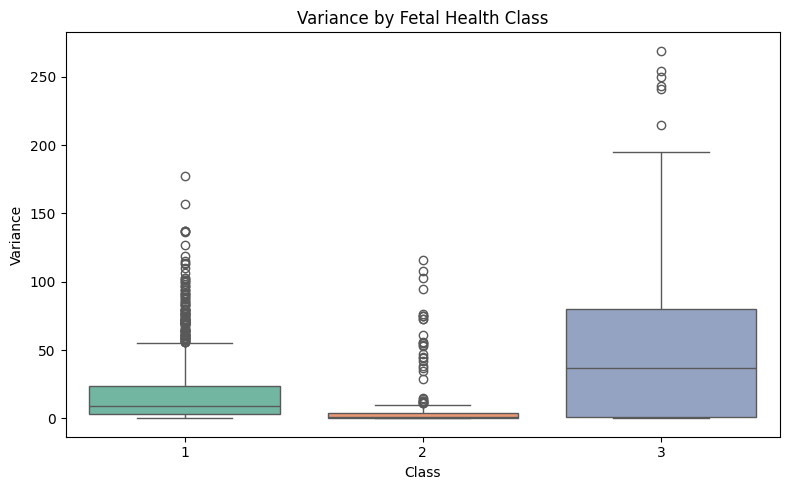

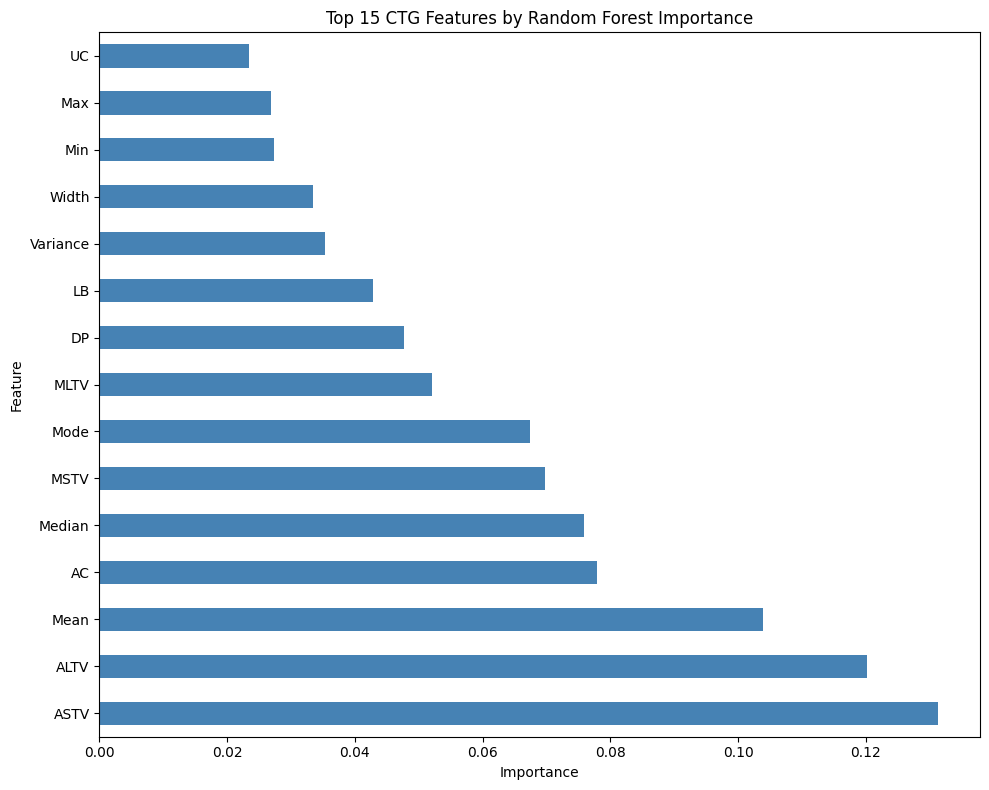

Top feature importance values:
 ASTV      0.131303
ALTV      0.120104
Mean      0.103832
AC        0.077912
Median    0.075804
MSTV      0.069716
Mode      0.067483
MLTV      0.052119
DP        0.047667
LB        0.042884
dtype: float64


In [15]:
# --- 1. Class distribution ---
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="NSP", palette="Set2")
plt.title("Class Distribution")
plt.xlabel("Fetal Health Class")
plt.ylabel("Count")
plt.xticks([0, 1, 2], [1, 2, 3])
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# --- 2. Correlation heatmap ---
plt.figure(figsize=(16, 12))
correlation = X.corr()
sns.heatmap(correlation, cmap="coolwarm", annot=False, fmt=".2f")
plt.title("Correlation Heatmap of CTG Features")
plt.tight_layout()
plt.savefig(PLOT_DIR / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# --- 3. Feature distributions ---
selected_features = [
    "LB", "AC", "UC", "ASTV", "MSTV", "ALTV", "MLTV", "Width", "Mean", "Variance", "Mode"
]
for col in selected_features:
    if col in X.columns:
        plt.figure(figsize=(7, 4))
        sns.histplot(X[col], kde=True, bins=30)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.savefig(PLOT_DIR / f"distribution_{col.lower()}.png", dpi=200, bbox_inches="tight")
        plt.show()

# --- 4. Boxplots by class for key features ---
for col in ["LB", "ASTV", "MSTV", "Mean", "Mode", "Variance"]:
    if col in X.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x="NSP", y=col, palette="Set2")
        plt.title(f"{col} by Fetal Health Class")
        plt.xlabel("Class")
        plt.ylabel(col)
        plt.xticks([0, 1, 2], [1, 2, 3])
        plt.tight_layout()
        plt.savefig(PLOT_DIR / f"boxplot_{col.lower()}_by_class.png", dpi=200, bbox_inches="tight")
        plt.show()

# --- 5. Random Forest feature importance ---
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importance.head(15).plot(kind="barh", color="steelblue")
plt.title("Top 15 CTG Features by Random Forest Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(PLOT_DIR / "random_forest_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

print("Top feature importance values:\n", importance.head(10))

## Random Forest baseline

Accuracy: 0.9272
Macro precision: 0.8641
Macro recall: 0.8969
Macro F1: 0.8793

Confusion matrix:
 [[314  16   2]
 [  8  49   2]
 [  1   2  32]]

Classification report:

              precision    recall  f1-score   support

           1      0.972     0.946     0.959       332
           2      0.731     0.831     0.778        59
           3      0.889     0.914     0.901        35

    accuracy                          0.927       426
   macro avg      0.864     0.897     0.879       426
weighted avg      0.932     0.927     0.929       426



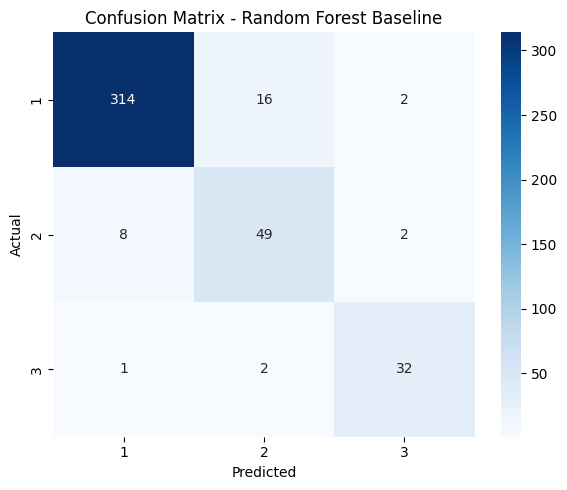

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
    )),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Accuracy: {acc:.4f}")
print(f"Macro precision: {prec:.4f}")
print(f"Macro recall: {rec:.4f}")
print(f"Macro F1: {f1:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
plt.title("Confusion Matrix - Random Forest Baseline")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(PLOT_DIR / "baseline_random_forest_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## Class-imbalance experiments

In [17]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline

imbalance_variants = {
    "Random Forest (unweighted)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42)),
    ]),
    "Random Forest (class_weight=balanced)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
        )),
    ]),
    "Random Forest (SMOTE)": ImbalancedPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42)),
    ]),
}

imbalance_results = []
for name, candidate in imbalance_variants.items():
    candidate.fit(X_train, y_train)
    prediction = candidate.predict(X_test)
    class_recalls = recall_score(y_test, prediction, average=None, labels=[1, 2, 3])
    imbalance_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision_macro": precision_score(y_test, prediction, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, prediction, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, prediction, average="macro", zero_division=0),
        "Recall_class_1": class_recalls[0],
        "Recall_class_2": class_recalls[1],
        "Recall_class_3": class_recalls[2],
    })
    print(f"\n{name} confusion matrix:\n", confusion_matrix(y_test, prediction, labels=[1, 2, 3]))

imbalance_comparison = pd.DataFrame(imbalance_results).sort_values(
    "F1_macro", ascending=False
).reset_index(drop=True)
print("\nClass-imbalance comparison:\n")
print(imbalance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))


Random Forest (unweighted) confusion matrix:
 [[326   4   2]
 [ 15  41   3]
 [  2   3  30]]

Random Forest (class_weight=balanced) confusion matrix:
 [[314  17   1]
 [  8  49   2]
 [  1   2  32]]

Random Forest (SMOTE) confusion matrix:
 [[319  11   2]
 [  7  48   4]
 [  1   2  32]]

Class-imbalance comparison:

                           Experiment  Accuracy  Precision_macro  Recall_macro  F1_macro  Recall_class_1  Recall_class_2  Recall_class_3
                Random Forest (SMOTE)    0.9366           0.8682        0.8962    0.8816          0.9608          0.8136          0.9143
Random Forest (class_weight=balanced)    0.9272           0.8690        0.8969    0.8816          0.9458          0.8305          0.9143
           Random Forest (unweighted)    0.9319           0.8872        0.8447    0.8631          0.9819          0.6949          0.8571


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

imbalance_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
imbalance_cv_results = []
for name, candidate in imbalance_variants.items():
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        scoring="f1_macro",
        cv=imbalance_cv,
        n_jobs=1,
    )
    imbalance_cv_results.append({
        "Model": name,
        "CV_macro_F1_mean": scores.mean(),
        "CV_macro_F1_std": scores.std(),
    })

imbalance_cv_comparison = pd.DataFrame(imbalance_cv_results)
print("Five-fold stratified CV for imbalance strategies:\n")
print(imbalance_cv_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

Five-fold stratified CV for imbalance strategies:

                                Model  CV_macro_F1_mean  CV_macro_F1_std
           Random Forest (unweighted)            0.8985           0.0091
Random Forest (class_weight=balanced)            0.9019           0.0122
                Random Forest (SMOTE)            0.9118           0.0142


## Baseline comparison and stratified cross-validation

In [19]:
from pathlib import Path

import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Keep the 1/2/3 labels used by the baseline intact; boosted trees use encoded labels.
y_model = (df["NSP"] - 1).astype(int)
X_train_models, X_test_models, y_train_models, y_test_models = train_test_split(
    X,
    y_model,
    test_size=0.2,
    random_state=42,
    stratify=y_model,
)

# These are the existing classifier families plus LightGBM for the reference comparison.
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", class_weight="balanced", random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced")),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
        )),
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=42)),
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            objective="multi:softmax",
            num_class=3,
            eval_metric="mlogloss",
            random_state=42,
            n_estimators=200,
            learning_rate=0.05,
            max_depth=5,
        )),
    ]),
    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            objective="multiclass",
            num_class=3,
            n_estimators=200,
            learning_rate=0.05,
            random_state=42,
            verbosity=-1,
            n_jobs=1,
        )),
    ]),
    "MLP": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)),
    ]),
}

results = []
for name, candidate in models.items():
    candidate.fit(X_train_models, y_train_models)
    prediction = candidate.predict(X_test_models)
    class_recalls = recall_score(
        y_test_models, prediction, average=None, labels=[0, 1, 2], zero_division=0
    )
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_models, prediction),
        "Precision_macro": precision_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test_models, prediction, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_class_1": class_recalls[0],
        "Recall_class_2": class_recalls[1],
        "Recall_class_3": class_recalls[2],
    })

comparison = pd.DataFrame(results).sort_values("F1_macro", ascending=False).reset_index(drop=True)
print("\nExisting-model holdout comparison:\n")
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(f"\nTop holdout model: {comparison.iloc[0]['Model']}")


Existing-model holdout comparison:

              Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Recall_class_1  Recall_class_2  Recall_class_3
            XGBoost    0.9460           0.9185        0.8863    0.9009          0.9819          0.7627          0.9143
           LightGBM    0.9437           0.9092        0.8807    0.8930          0.9819          0.7458          0.9143
  Gradient Boosting    0.9437           0.9072        0.8807    0.8913          0.9819          0.7458          0.9143
      Random Forest    0.9272           0.8690        0.8969    0.8816          0.9458          0.8305          0.9143
      Decision Tree    0.9178           0.8560        0.8526    0.8541          0.9548          0.7458          0.8571
                MLP    0.9178           0.8559        0.8348    0.8446          0.9639          0.7119          0.8286
                SVM    0.8685           0.7673        0.8431    0.7912          0.8765          0.8814          0.7714
Logistic Re

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

selection_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_selection_results = []
for name, candidate in models.items():
    scores = cross_val_score(
        candidate,
        X_train_models,
        y_train_models,
        scoring="f1_macro",
        cv=selection_cv,
        n_jobs=1,
    )
    cv_selection_results.append({
        "Model": name,
        "CV_macro_F1_mean": scores.mean(),
        "CV_macro_F1_std": scores.std(),
    })

cv_selection = pd.DataFrame(cv_selection_results).sort_values(
    "CV_macro_F1_mean", ascending=False
).reset_index(drop=True)
print("Five-fold stratified CV on the training partition:\n")
print(cv_selection.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print("\nTuning candidates selected by CV:", cv_selection.head(2)["Model"].tolist())

Five-fold stratified CV on the training partition:

              Model  CV_macro_F1_mean  CV_macro_F1_std
            XGBoost            0.9218           0.0068
  Gradient Boosting            0.9211           0.0161
           LightGBM            0.9190           0.0074
      Random Forest            0.9019           0.0122
                MLP            0.8807           0.0291
      Decision Tree            0.8764           0.0172
                KNN            0.8312           0.0136
                SVM            0.8208           0.0216
Logistic Regression            0.8043           0.0184

Tuning candidates selected by CV: ['XGBoost', 'Gradient Boosting']


## Hyperparameter tuning

In [21]:
from sklearn.model_selection import RandomizedSearchCV

search_spaces = {
    "XGBoost": {
        "model__n_estimators": [100, 150, 200, 300],
        "model__max_depth": [3, 4, 5],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__min_child_weight": [1, 3],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200, 300],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "LightGBM": {
        "model__n_estimators": [100, 150, 200, 300],
        "model__num_leaves": [15, 31, 63],
        "model__max_depth": [-1, 5, 10],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__min_child_samples": [10, 20],
        "model__colsample_bytree": [0.8, 1.0],
        "model__reg_lambda": [0.0, 1.0],
    },
}

tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned_models = {}
tuned_results = []

for name in cv_selection.head(2)["Model"]:
    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=search_spaces[name],
        n_iter=6,
        scoring="f1_macro",
        cv=tuning_cv,
        random_state=42,
        n_jobs=1,
        refit=True,
    )
    search.fit(X_train_models, y_train_models)
    tuned_models[name] = search.best_estimator_
    prediction = search.best_estimator_.predict(X_test_models)
    class_recalls = recall_score(
        y_test_models, prediction, average=None, labels=[0, 1, 2], zero_division=0
    )

    nested_search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=search_spaces[name],
        n_iter=6,
        scoring="f1_macro",
        cv=tuning_cv,
        random_state=42,
        n_jobs=1,
        refit=True,
    )
    nested_scores = cross_val_score(
        nested_search,
        X_train_models,
        y_train_models,
        scoring="f1_macro",
        cv=final_cv,
        n_jobs=1,
    )
    tuned_results.append({
        "Model": f"{name} (tuned)",
        "Accuracy": accuracy_score(y_test_models, prediction),
        "Precision_macro": precision_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test_models, prediction, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_class_1": class_recalls[0],
        "Recall_class_2": class_recalls[1],
        "Recall_class_3": class_recalls[2],
        "Nested_CV_macro_F1_mean": nested_scores.mean(),
        "Nested_CV_macro_F1_std": nested_scores.std(),
        "Best_parameters": search.best_params_,
    })
    print(f"\n{name} best parameters: {search.best_params_}")
    print(f"{name} inner CV best macro F1: {search.best_score_:.4f}")
    print(f"{name} nested five-fold CV macro F1: {nested_scores.mean():.4f} +/- {nested_scores.std():.4f}")

print("\nTuned-model holdout results:\n")
print(pd.DataFrame(tuned_results).drop(columns="Best_parameters").to_string(
    index=False, float_format=lambda value: f"{value:.4f}"
))


XGBoost best parameters: {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}
XGBoost inner CV best macro F1: 0.9236
XGBoost nested five-fold CV macro F1: 0.9274 +/- 0.0058

Gradient Boosting best parameters: {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 4, 'model__max_depth': 2, 'model__learning_rate': 0.1}
Gradient Boosting inner CV best macro F1: 0.9261
Gradient Boosting nested five-fold CV macro F1: 0.9155 +/- 0.0129

Tuned-model holdout results:

                    Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Recall_class_1  Recall_class_2  Recall_class_3  Nested_CV_macro_F1_mean  Nested_CV_macro_F1_std
          XGBoost (tuned)    0.9531           0.9245        0.8947    0.9084          0.9849          0.8136          0.8857                   0.9274                  0.0058
Gradient Boosting (tuned)    0.9484          

## Feature-selection experiment

In [22]:
from sklearn.base import clone

feature_selection_results = []
baseline_xgb = comparison.loc[comparison["Model"] == "XGBoost"].iloc[0]
feature_selection_results.append({
    "Experiment": "Feature selection",
    "Model": f"XGBoost (all {len(FEATURE_COLS)})",
    "Accuracy": baseline_xgb["Accuracy"],
    "Precision_macro": baseline_xgb["Precision_macro"],
    "Recall_macro": baseline_xgb["Recall_macro"],
    "F1_macro": baseline_xgb["F1_macro"],
    "Recall_class_1": baseline_xgb["Recall_class_1"],
    "Recall_class_2": baseline_xgb["Recall_class_2"],
    "Recall_class_3": baseline_xgb["Recall_class_3"],
    "CV_macro_F1_mean": np.nan,
    "CV_macro_F1_std": np.nan,
    "Feature_count": len(FEATURE_COLS),
    "Selected_features": ", ".join(FEATURE_COLS),
})

for feature_count in (10, 15):
    selected_features = importance.index[:feature_count].tolist()
    candidate = clone(models["XGBoost"])
    candidate.fit(X_train_models.loc[:, selected_features], y_train_models)
    prediction = candidate.predict(X_test_models.loc[:, selected_features])
    class_recalls = recall_score(
        y_test_models, prediction, average=None, labels=[0, 1, 2], zero_division=0
    )
    feature_selection_results.append({
        "Experiment": "Feature selection",
        "Model": f"XGBoost (top {feature_count})",
        "Accuracy": accuracy_score(y_test_models, prediction),
        "Precision_macro": precision_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test_models, prediction, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test_models, prediction, average="macro", zero_division=0),
        "Recall_class_1": class_recalls[0],
        "Recall_class_2": class_recalls[1],
        "Recall_class_3": class_recalls[2],
        "CV_macro_F1_mean": np.nan,
        "CV_macro_F1_std": np.nan,
        "Feature_count": feature_count,
        "Selected_features": ", ".join(selected_features),
    })
    print(f"\nTop {feature_count} selected features: {selected_features}")

feature_selection_comparison = pd.DataFrame(feature_selection_results)
print("\nXGBoost feature-selection holdout comparison:\n")
print(feature_selection_comparison.drop(columns="Selected_features").to_string(
    index=False, float_format=lambda value: f"{value:.4f}"
))


Top 10 selected features: ['ASTV', 'ALTV', 'Mean', 'AC', 'Median', 'MSTV', 'Mode', 'MLTV', 'DP', 'LB']

Top 15 selected features: ['ASTV', 'ALTV', 'Mean', 'AC', 'Median', 'MSTV', 'Mode', 'MLTV', 'DP', 'LB', 'Variance', 'Width', 'Min', 'Max', 'UC']

XGBoost feature-selection holdout comparison:

       Experiment            Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Recall_class_1  Recall_class_2  Recall_class_3  CV_macro_F1_mean  CV_macro_F1_std  Feature_count
Feature selection XGBoost (all 22)    0.9460           0.9185        0.8863    0.9009          0.9819          0.7627          0.9143               NaN              NaN             22
Feature selection XGBoost (top 10)    0.9390           0.9046        0.8740    0.8862          0.9789          0.7288          0.9143               NaN              NaN             10
Feature selection XGBoost (top 15)    0.9437           0.9128        0.8853    0.8979          0.9789          0.7627          0.9143               NaN

## Final comparison and model artifact

In [23]:
import pickle
from pathlib import Path

baseline_final = comparison.merge(
    cv_selection,
    on="Model",
    how="left",
).copy()
baseline_final.insert(0, "Experiment", "Baseline")
baseline_final["Feature_count"] = len(FEATURE_COLS)
baseline_final["Selected_features"] = ", ".join(FEATURE_COLS)

imbalance_final = imbalance_comparison.rename(columns={"Experiment": "Model"}).merge(
    imbalance_cv_comparison,
    on="Model",
    how="left",
)
imbalance_final.insert(0, "Experiment", "Class imbalance")
imbalance_final["Feature_count"] = len(FEATURE_COLS)
imbalance_final["Selected_features"] = ", ".join(FEATURE_COLS)

tuned_final = pd.DataFrame(tuned_results).drop(columns="Best_parameters").copy()
tuned_final.insert(0, "Experiment", "Tuned")
tuned_final = tuned_final.rename(columns={
    "Nested_CV_macro_F1_mean": "CV_macro_F1_mean",
    "Nested_CV_macro_F1_std": "CV_macro_F1_std",
})
tuned_final["Feature_count"] = len(FEATURE_COLS)
tuned_final["Selected_features"] = ", ".join(FEATURE_COLS)

final_columns = [
    "Experiment", "Model", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro",
    "Recall_class_1", "Recall_class_2", "Recall_class_3", "CV_macro_F1_mean", "CV_macro_F1_std",
    "Feature_count", "Selected_features",
]
final_comparison = pd.concat(
    [
        baseline_final[final_columns],
        imbalance_final[final_columns],
        tuned_final[final_columns],
        feature_selection_comparison[final_columns],
    ],
    ignore_index=True,
).sort_values("F1_macro", ascending=False).reset_index(drop=True)

print("Final experiment comparison (holdout metrics; CV is training-only):\n")
print(final_comparison.drop(columns="Selected_features").to_string(
    index=False, float_format=lambda value: f"{value:.4f}"
))

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)
final_comparison.to_csv(results_dir / "model_comparison.csv", index=False)
print(f"\nSaved final comparison to: {results_dir / 'model_comparison.csv'}")

best_tuned = max(tuned_results, key=lambda result: result["Nested_CV_macro_F1_mean"])
best_model_name = best_tuned["Model"].replace(" (tuned)", "")
model_dir = Path("../models")
model_dir.mkdir(exist_ok=True)
with open(model_dir / "final_model.pkl", "wb") as model_file:
    pickle.dump(tuned_models[best_model_name], model_file)
with open(model_dir / "fetal_health_model.pkl", "wb") as model_file:
    pickle.dump(tuned_models[best_model_name], model_file)
print(f"Saved selected model ({best_model_name}) using nested-CV macro F1.")

Final experiment comparison (holdout metrics; CV is training-only):

       Experiment                                 Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Recall_class_1  Recall_class_2  Recall_class_3  CV_macro_F1_mean  CV_macro_F1_std  Feature_count
            Tuned                       XGBoost (tuned)    0.9531           0.9245        0.8947    0.9084          0.9849          0.8136          0.8857            0.9274           0.0058             22
            Tuned             Gradient Boosting (tuned)    0.9484           0.9271        0.8827    0.9011          0.9880          0.7458          0.9143            0.9155           0.0129             22
         Baseline                               XGBoost    0.9460           0.9185        0.8863    0.9009          0.9819          0.7627          0.9143            0.9218           0.0068             22
Feature selection                      XGBoost (all 22)    0.9460           0.9185        0.8863    0.9009     

## Final tuned-model diagnostics

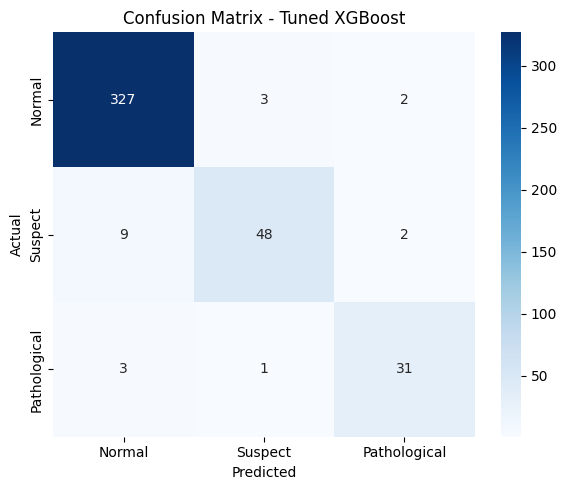

              precision    recall  f1-score   support

      Normal     0.9646    0.9849    0.9747       332
     Suspect     0.9231    0.8136    0.8649        59
Pathological     0.8857    0.8857    0.8857        35

    accuracy                         0.9531       426
   macro avg     0.9245    0.8947    0.9084       426
weighted avg     0.9524    0.9531    0.9521       426



In [24]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

final_model = tuned_models[best_model_name]
final_pred = final_model.predict(X_test_models)

cm = confusion_matrix(
    y_test_models,
    final_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathological"],
    yticklabels=["Normal", "Suspect", "Pathological"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - Tuned {best_model_name}")
plt.tight_layout()
plt.savefig(PLOT_DIR / "final_model_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print(classification_report(
    y_test_models,
    final_pred,
    target_names=["Normal", "Suspect", "Pathological"],
    digits=4
))